# Classification

In [1]:
# Importing the modules
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report, confusion_matrix, roc_curve, f1_score, auc

## Loading the Dataset

In [2]:
dataset=load_breast_cancer(as_frame=True)

## Converting the dataset to a dataframe

In [3]:
data=dataset.frame

## Viewing the first 10 rows of the dataset

In [4]:
data.head(10)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0
5,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,0.2087,0.07613,...,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440,0
6,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,0.1794,0.05742,...,27.66,153.20,1606.0,0.1442,0.2576,0.3784,0.1932,0.3063,0.08368,0
7,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,0.2196,0.07451,...,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.1556,0.3196,0.11510,0
8,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,0.2350,0.07389,...,30.73,106.20,739.3,0.1703,0.5401,0.5390,0.2060,0.4378,0.10720,0
9,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,0.2030,0.08243,...,40.68,97.65,711.4,0.1853,1.0580,1.1050,0.2210,0.4366,0.20750,0


## Displaying information about the dataset

In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

## Statistical analysis of the dataset

In [6]:
data.drop('target', axis=1).describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


## Checking for duplicate rows

In [7]:
data.duplicated().sum()

np.int64(0)

***No duplicate rows have been identified in the dataset.***

## Checking for missing values

In [8]:
data.isna().sum()

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

***No missing values have been identified in the dataset.***

## Creating a copy of the dataset

In [9]:
data_copy=data.copy()
# Removing the target column for running different analysis on the feature columns
data_copy.drop('target', axis=1, inplace=True)

## Analyzing the columns

### Checking for outliers

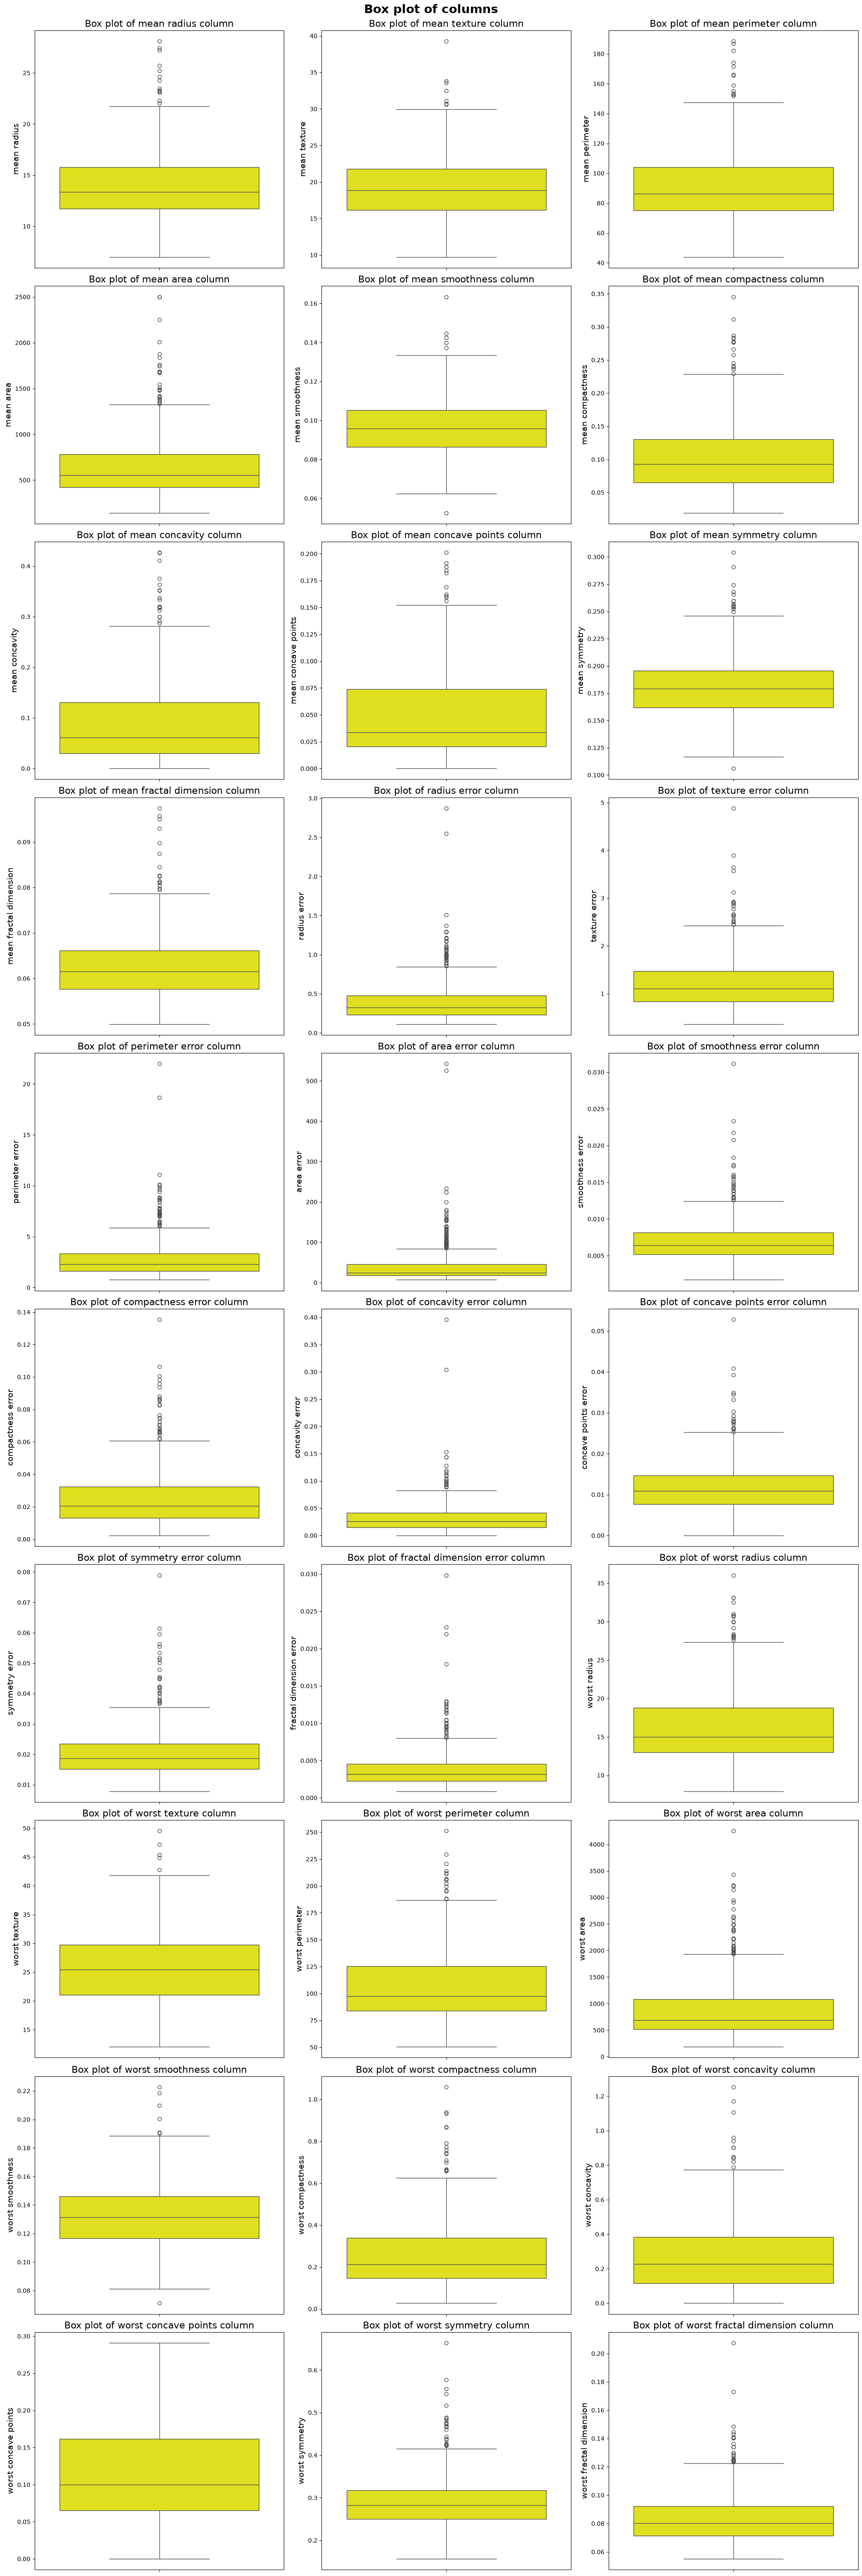

In [10]:
fig, ax=plt.subplots(10,3, figsize=(20,60), constrained_layout=True)
columns=data_copy.columns
count=0
for i in range(10):
    for j in range(3):
        sns.boxplot(
            data=data_copy,
            y=columns[count],
            color='yellow',
            ax=ax[i][j]
        )
        ax[i][j].set_title(f"Box plot of {columns[count]} column", fontsize=16)
        ax[i][j].set_ylabel(columns[count], fontsize=14)
        count+=1
fig.suptitle("Box plot of columns",fontsize=20, fontweight="bold")
plt.show()

***Outliers have been identified in all columns except 'worst concave points' column.***

### Checking for skewness

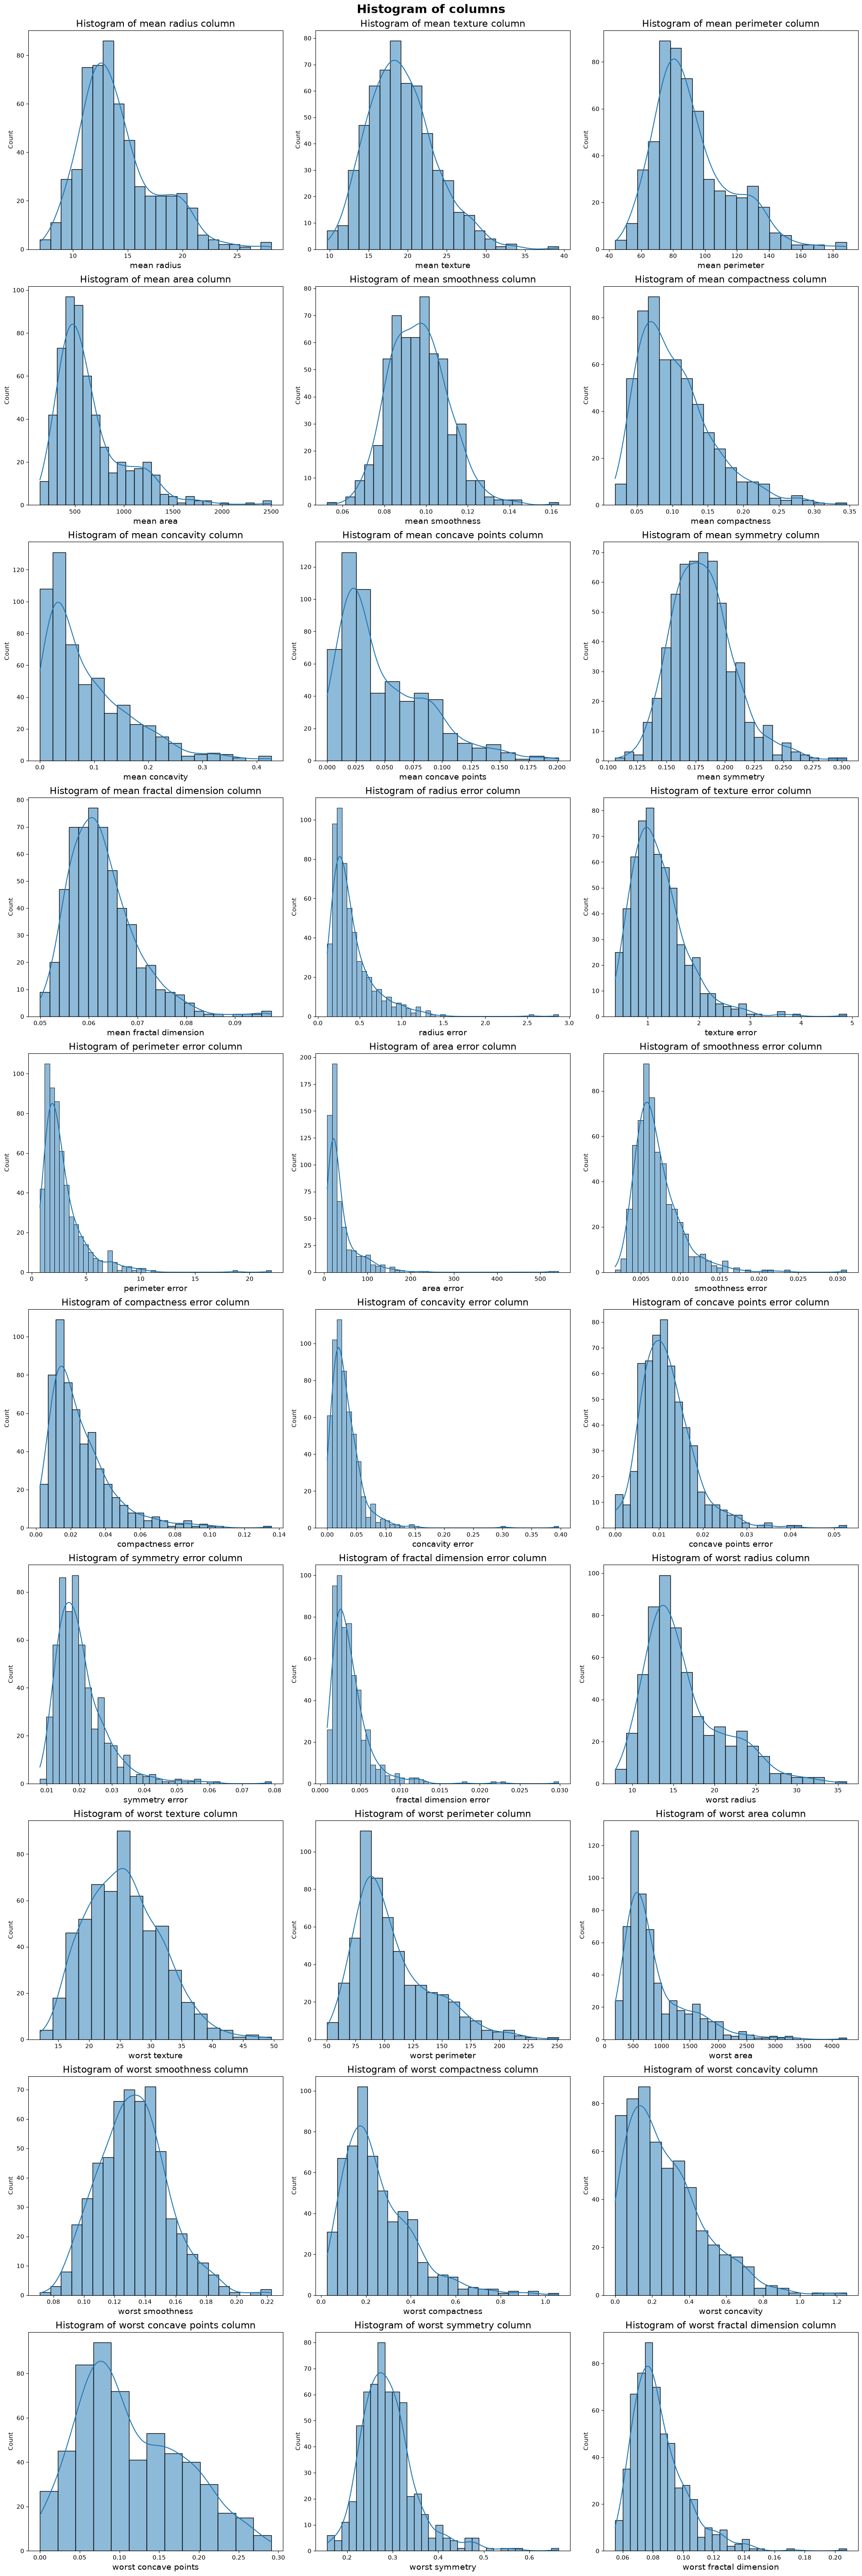

In [11]:
fig, ax=plt.subplots(10,3, figsize=(20,60), constrained_layout=True)
count=0
for i in range(10):
    for j in range(3):
        sns.histplot(
            data=data_copy,
            x=columns[count],
            kde=True,
            ax=ax[i][j]
        )
        ax[i][j].set_title(f"Histogram of {columns[count]} column", fontsize=16)
        ax[i][j].set_xlabel(columns[count], fontsize=14)
        count+=1
fig.suptitle("Histogram of columns",fontsize=20, fontweight="bold")
plt.show()

In [12]:
# Checking for skewness
skew_dataframe=data_copy.skew().reset_index()
skew_dataframe.columns=['column', 'skewness']
skew_dataframe

,column,skewness
0,mean radius,0.942380
1,mean texture,0.650450
2,mean perimeter,0.990650
3,mean area,1.645732
4,mean smoothness,0.456324
5,mean compactness,1.190123
6,mean concavity,1.401180
7,mean concave points,1.171180
8,mean symmetry,0.725609
9,mean fractal dimension,1.304489


In [13]:
# Fetching highly skewed columns
highly_skewed_dataframe=skew_dataframe[skew_dataframe.skewness>1]
highly_skewed_dataframe

,column,skewness
3,mean area,1.645732
5,mean compactness,1.190123
6,mean concavity,1.401180
7,mean concave points,1.171180
9,mean fractal dimension,1.304489
10,radius error,3.088612
11,texture error,1.646444
12,perimeter error,3.443615
13,area error,5.447186
14,smoothness error,2.314450


In [14]:
# creating a list of highly skewed columns
highly_skewed_columns=highly_skewed_dataframe['column'].tolist()
print(f"Highly skewed columns are: {highly_skewed_columns}")

Highly skewed columns are: ['mean area', 'mean compactness', 'mean concavity', 'mean concave points', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst perimeter', 'worst area', 'worst compactness', 'worst concavity', 'worst symmetry', 'worst fractal dimension']


In [15]:
# Fetching moderately skewed columns
moderately_skewed_dataframe=skew_dataframe[(skew_dataframe.skewness<=1) & (skew_dataframe.skewness>=0.5)]
moderately_skewed_dataframe

,column,skewness
0,mean radius,0.942380
1,mean texture,0.650450
2,mean perimeter,0.990650
8,mean symmetry,0.725609


In [16]:
# creating a list of moderately skewed columns
moderately_skewed_columns=moderately_skewed_dataframe['column'].tolist()
print(f"Moderately skewed columns are: {moderately_skewed_columns}")

Moderately skewed columns are: ['mean radius', 'mean texture', 'mean perimeter', 'mean symmetry']


In [17]:
# Fetching fairly symmetric columns
fairly_symmetric_dataframe=skew_dataframe[skew_dataframe.skewness<0.5]
fairly_symmetric_dataframe

,column,skewness
4,mean smoothness,0.456324
21,worst texture,0.498321
24,worst smoothness,0.415426
27,worst concave points,0.492616


In [18]:
# creating a list of fairly symmetric columns
fairly_symmetric_columns=fairly_symmetric_dataframe['column'].tolist()
print(f"Fairly symmetric solumns are: {fairly_symmetric_columns}")

Fairly symmetric solumns are: ['mean smoothness', 'worst texture', 'worst smoothness', 'worst concave points']


## Selecting the target

In [19]:
y=data['target']

## Selecting the features

In [20]:
X=data.drop('target', axis=1)

## Train - Test split

In [21]:
X_train, X_test, y_train, y_test=train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

## Transformation

#### Appying **log** transformation to highly skewed columns.

In [22]:
X_train[highly_skewed_columns]=np.log1p(X_train[highly_skewed_columns])
X_test[highly_skewed_columns]=np.log1p(X_test[highly_skewed_columns])

#### Applying **squareroot** transformation to moderately skewed columns.

In [23]:
X_train[moderately_skewed_columns]=np.sqrt(X_train[moderately_skewed_columns])
X_test[moderately_skewed_columns]=np.sqrt(X_test[moderately_skewed_columns])

## Scaling

In [24]:
standard_scaler=StandardScaler()
X_train_scaled=standard_scaler.fit_transform(X_train)
X_test_scaled=standard_scaler.transform(X_test)

***Standard scaling is done on the feature columns to scale them all to a common range.***

## Training the models

### **Logistic Regression**

***Logistic Regression is a supervised learning algorithm used for classification. It classifies data into categories or classes by predicting the probability that an observation falls into a particular class based on its features. Uses Sigmoid function.***

In [25]:
logistic_regression=LogisticRegression()
logistic_regression.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

#### Prediction

In [26]:
y_pred_logistic_regression=logistic_regression.predict(X_test_scaled)

#### Accuracy

In [27]:
accuracy_logistic_regression=accuracy_score(y_true=y_test, y_pred=y_pred_logistic_regression)
print(f"Accuracy: {accuracy_logistic_regression}")

Accuracy: 0.9736842105263158


#### Precision

In [28]:
precision_logistic_regression=precision_score(y_true=y_test, y_pred=y_pred_logistic_regression)
print(f"Precision: {precision_logistic_regression}")

Precision: 0.9859154929577465


#### Recall

In [29]:
recall_logistic_regression=recall_score(y_true=y_test, y_pred=y_pred_logistic_regression)
print(f"Recall: {recall_logistic_regression}")

Recall: 0.9722222222222222


#### F1 Score

In [30]:
f1_score_logistic_regression=f1_score(y_true=y_test, y_pred=y_pred_logistic_regression)
print(f"F1 Score: {f1_score_logistic_regression}")

F1 Score: 0.9790209790209791


#### Confusion Matrix

In [31]:
confusion_matrix_logistic_regression=confusion_matrix(y_true=y_test, y_pred=y_pred_logistic_regression)
print("Confusion Matrix")
confusion_matrix_logistic_regression

Confusion Matrix


array([[41,  1],
       [ 2, 70]])

#### Classification Report

In [32]:
classification_report_logistic_regression=classification_report(y_true=y_test, y_pred=y_pred_logistic_regression)
print("Classification Report")
print(classification_report_logistic_regression)

Classification Report
              precision    recall  f1-score   support

           0       0.95      0.98      0.96        42
           1       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



### **Decision Tree Classifier**

***Decision Tree Classifier is a supervised learning algorithm used for classification. It creates a tree like structure where the internal nodes represents the features and branches represent the rules. The tree starts from the root node and ends in leaf node indicating the results.***

In [33]:
decision_tree_classifier=DecisionTreeClassifier(random_state=42)
decision_tree_classifier.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

#### Prediction

In [34]:
y_pred_decision_tree_classifier=decision_tree_classifier.predict(X_test_scaled)

#### Accuracy

In [35]:
accuracy_decision_tree_classifier=accuracy_score(y_true=y_test, y_pred=y_pred_decision_tree_classifier)
print(f"Accuracy: {accuracy_decision_tree_classifier}")

Accuracy: 0.9122807017543859


#### Precision

In [36]:
precision_decision_tree_classifier=precision_score(y_true=y_test, y_pred=y_pred_decision_tree_classifier)
print(f"Precision: {precision_decision_tree_classifier}")

Precision: 0.9558823529411765


#### Recall

In [37]:
recall_decision_tree_classifier=recall_score(y_true=y_test, y_pred=y_pred_decision_tree_classifier)
print(f"Recall: {recall_decision_tree_classifier}")

Recall: 0.9027777777777778


#### F1 Score

In [38]:
f1_score_decision_tree_classifier=f1_score(y_true=y_test, y_pred=y_pred_decision_tree_classifier)
print(f"F1 Score: {f1_score_decision_tree_classifier}")

F1 Score: 0.9285714285714286


#### Confusion Matrix

In [39]:
confusion_matrix_decision_tree_classifier=confusion_matrix(y_true=y_test, y_pred=y_pred_decision_tree_classifier)
print("Confusion Matrix")
confusion_matrix_decision_tree_classifier

Confusion Matrix


array([[39,  3],
       [ 7, 65]])

#### Classification Report

In [40]:
classification_report_decision_tree_classifier=classification_report(y_true=y_test, y_pred=y_pred_decision_tree_classifier)
print("Classification Report")
print(classification_report_decision_tree_classifier)

Classification Report
              precision    recall  f1-score   support

           0       0.85      0.93      0.89        42
           1       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114



### **Random Forest Classifier**

***Random Forest Classifier is an ensemble learning technique that takes multiple samples from the dataset with replacement and trains a seperate decision tree model for each sample and takes the majority of the predictions made by all the trees as the final result.***

In [41]:
random_forest_classifier=RandomForestClassifier(random_state=42)
random_forest_classifier.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

#### Prediction

In [42]:
y_pred_random_forest_classifier=random_forest_classifier.predict(X_test_scaled)

#### Accuracy

In [43]:
accuracy_random_forest_classifier=accuracy_score(y_true=y_test, y_pred=y_pred_random_forest_classifier)
print(f"Accuracy: {accuracy_random_forest_classifier}")

Accuracy: 0.956140350877193


#### Precision

In [44]:
precision_random_forest_classifier=precision_score(y_true=y_test, y_pred=y_pred_random_forest_classifier)
print(f"Precision: {precision_random_forest_classifier}")

Precision: 0.958904109589041


#### Recall

In [45]:
recall_random_forest_classifier=recall_score(y_true=y_test, y_pred=y_pred_random_forest_classifier)
print(f"Recall: {recall_random_forest_classifier}")

Recall: 0.9722222222222222


#### F1 Score

In [46]:
f1_score_random_forest_classifier=f1_score(y_true=y_test, y_pred=y_pred_random_forest_classifier)
print(f"F1 score: {f1_score_random_forest_classifier}")

F1 score: 0.9655172413793104


#### Confusion Matrix

In [47]:
confusion_matrix_random_forest_classifier=confusion_matrix(y_true=y_test, y_pred=y_pred_random_forest_classifier)
print("Confusion Matrix")
confusion_matrix_random_forest_classifier

Confusion Matrix


array([[39,  3],
       [ 2, 70]])

#### Classification Report

In [48]:
classification_report_random_forest_classifier=classification_report(y_true=y_test, y_pred=y_pred_random_forest_classifier)
print("Classification Report")
print(classification_report_random_forest_classifier)

Classification Report
              precision    recall  f1-score   support

           0       0.95      0.93      0.94        42
           1       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



### **Support Vector Classifier**

***Support Vector Classifier is a supervised learning algorithm used for classification. It constructs a hyperplane in a high dimensional space to seperate the data points.***

In [49]:
support_vector_classifier=SVC(probability=True)
support_vector_classifier.fit(X_train_scaled, y_train)

c:\Users\nipin\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",True
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


#### Prediction

In [50]:
y_pred_svc=support_vector_classifier.predict(X_test_scaled)

#### Accuracy

In [51]:
accuracy_svc=accuracy_score(y_true=y_test, y_pred=y_pred_svc)
print(f"Accuracy: {accuracy_svc}")

Accuracy: 0.9824561403508771


#### Precision

In [52]:
precision_svc=precision_score(y_true=y_test, y_pred=y_pred_svc)
print(f"Precision: {precision_svc}")

Precision: 0.9861111111111112


#### Recall

In [53]:
recall_svc=recall_score(y_true=y_test, y_pred=y_pred_svc)
print(f"Recall: {recall_svc}")

Recall: 0.9861111111111112


#### F1 Score

In [54]:
f1_score_svc=f1_score(y_true=y_test, y_pred=y_pred_svc)
print(f"F1 Score: {f1_score_svc}")

F1 Score: 0.9861111111111112


#### Confusion Matrix

In [55]:
confusion_matrix_svc=confusion_matrix(y_true=y_test, y_pred=y_pred_svc)
print("Confusion Matrix")
confusion_matrix_svc

Confusion Matrix


array([[41,  1],
       [ 1, 71]])

#### Classification Report

In [56]:
classification_report_svc=classification_report(y_true=y_test, y_pred=y_pred_svc)
print("Classification Report")
print(classification_report_svc)

Classification Report
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



### **k - Nearest Neighbor**

**k - Nearest Neighbor is a supervised learning algorithm that can be used for both classification and regression. For classification, it identifies the nearest points to the new data point and takes majority.**

In [57]:
knn=KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


#### Prediction

In [58]:
y_pred_knn=knn.predict(X_test_scaled)

#### Accuracy

In [59]:
accuracy_knn=accuracy_score(y_true=y_test, y_pred=y_pred_knn)
print(f"Accuracy: {accuracy_knn}")

Accuracy: 0.9649122807017544


#### Precision

In [60]:
precision_knn=precision_score(y_true=y_test, y_pred=y_pred_knn)
print(f"Precision: {precision_knn}")

Precision: 0.9594594594594594


#### Recall

In [61]:
recall_knn=recall_score(y_true=y_test, y_pred=y_pred_knn)
print(f"Recall: {recall_knn}")

Recall: 0.9861111111111112


#### F1 Score

In [62]:
f1_score_knn=f1_score(y_true=y_test, y_pred=y_pred_knn)
print(f"F1 Score: {f1_score_knn}")

F1 Score: 0.9726027397260274


#### Confusion Matrix

In [63]:
confusion_matrix_knn=confusion_matrix(y_true=y_test, y_pred=y_pred_knn)
print("Confusion Matrix")
confusion_matrix_knn

Confusion Matrix


array([[39,  3],
       [ 1, 71]])

####  Classification Report

In [64]:
classification_report_knn=classification_report(y_true=y_test, y_pred=y_pred_knn)
print("Classification Report")
print(classification_report_knn)

Classification Report
              precision    recall  f1-score   support

           0       0.97      0.93      0.95        42
           1       0.96      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



## Comparing the models

#### Creating a dataframe for comparison

In [65]:
# Creating a dataframe
comparison=pd.DataFrame(
    {
        "model":['Logistic Regression', 'Decision Tree Classifier', 'Random Forest Classifier', 'Support Vector Classifier', 'k-Nearest Neighbors'],
        "accuracy":[accuracy_logistic_regression, accuracy_decision_tree_classifier, accuracy_random_forest_classifier, accuracy_svc, accuracy_knn],
        "precision":[precision_logistic_regression, precision_decision_tree_classifier, precision_random_forest_classifier, precision_svc, precision_knn],
        "recall":[recall_logistic_regression, recall_decision_tree_classifier, recall_random_forest_classifier, recall_svc, recall_knn],
        "f1_score":[f1_score_logistic_regression, f1_score_decision_tree_classifier, f1_score_random_forest_classifier, f1_score_svc, f1_score_knn]
    }
)

In [66]:
comparison

,model,accuracy,precision,recall,f1_score
0,Logistic Regression,0.973684,0.985915,0.972222,0.979021
1,Decision Tree Classifier,0.912281,0.955882,0.902778,0.928571
2,Random Forest Classifier,0.956140,0.958904,0.972222,0.965517
3,Support Vector Classifier,0.982456,0.986111,0.986111,0.986111
4,k-Nearest Neighbors,0.964912,0.959459,0.986111,0.972603


#### Plotting a graph for comparing models

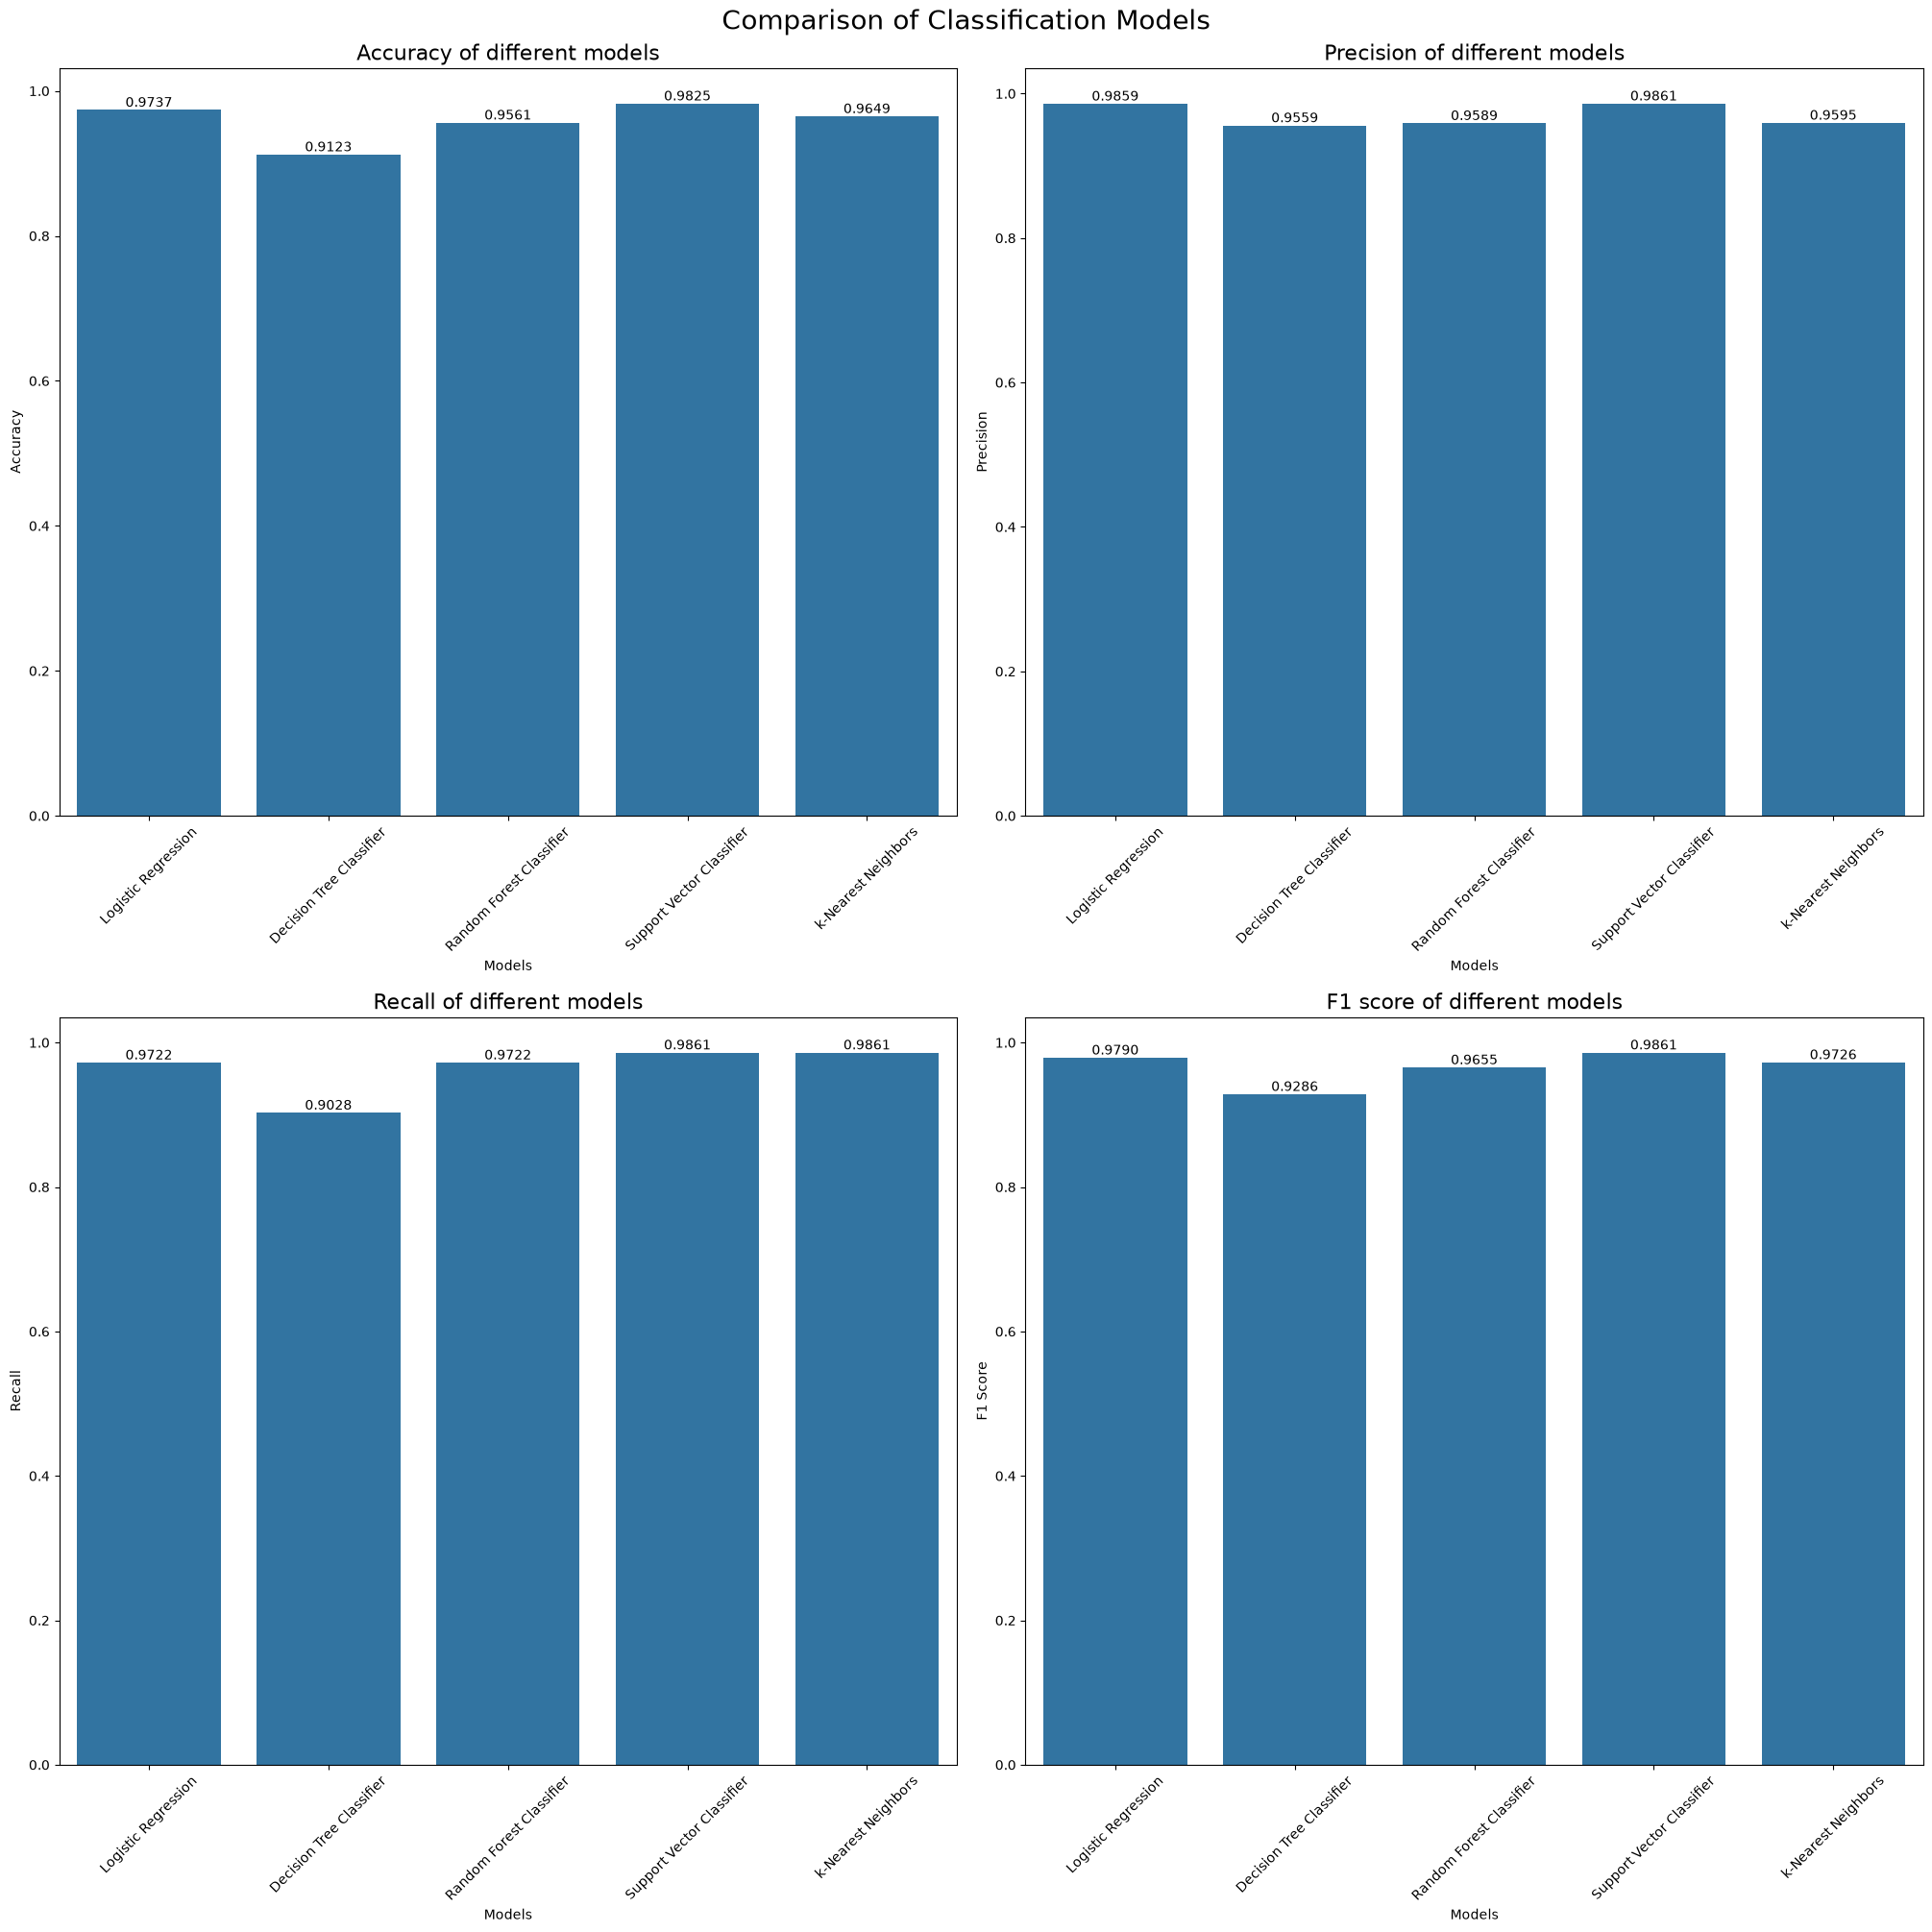

In [67]:
fig, ax=plt.subplots(2,2, figsize=(20,20), constrained_layout=True)
accuracy_plot=sns.barplot(data=comparison, x='model', y='accuracy', ax=ax[0][0])
ax[0][0].set_title("Accuracy of different models", fontsize=16)
ax[0][0].set_xlabel("Models")
ax[0][0].set_ylabel("Accuracy")
ax[0][0].bar_label(accuracy_plot.containers[0], fmt='%.4f')
ax[0][0].tick_params(axis='x', rotation=45)
precision_plot=sns.barplot(data=comparison, x='model', y='precision', ax=ax[0][1])
ax[0][1].set_title("Precision of different models", fontsize=16)
ax[0][1].set_xlabel("Models")
ax[0][1].set_ylabel("Precision")
ax[0][1].bar_label(precision_plot.containers[0], fmt='%.4f')
ax[0][1].tick_params(axis='x', rotation=45)
recall_plot=sns.barplot(data=comparison, x='model', y='recall', ax=ax[1][0])
ax[1][0].set_title("Recall of different models", fontsize=16)
ax[1][0].set_xlabel("Models")
ax[1][0].set_ylabel("Recall")
ax[1][0].bar_label(recall_plot.containers[0], fmt='%.4f')
ax[1][0].tick_params(axis='x', rotation=45)
f1_plot=sns.barplot(data=comparison, x='model', y='f1_score', ax=ax[1][1])
ax[1][1].set_title("F1 score of different models", fontsize=16)
ax[1][1].set_xlabel("Models")
ax[1][1].set_ylabel("F1 Score")
ax[1][1].bar_label(f1_plot.containers[0], fmt='%.4f')
ax[1][1].tick_params(axis='x', rotation=45)
fig.suptitle("Comparison of Classification Models", fontsize=20)
plt.show()

#### ROC Curve

In [68]:
curve_dataframe=pd.DataFrame(
    {
        "True":y_test,
        "Logistic Regression":logistic_regression.predict_proba(X_test_scaled)[:,1],
        "Decision Tree Classifier":decision_tree_classifier.predict_proba(X_test_scaled)[:,1],
        "Random Forest Classifier":random_forest_classifier.predict_proba(X_test_scaled)[:,1],
        "Support Vector Classifier":support_vector_classifier.predict_proba(X_test_scaled)[:,1],
        "KNN":knn.predict_proba(X_test_scaled)[:,1]
    }
)
curve_dataframe

,True,Logistic Regression,Decision Tree Classifier,Random Forest Classifier,Support Vector Classifier,KNN
256,0,1.302629e-06,0.0,0.00,0.001475,0.0
428,1,9.999972e-01,1.0,1.00,0.999998,1.0
501,0,3.519516e-03,0.0,0.12,0.006657,0.0
363,1,5.408700e-01,1.0,0.28,0.467388,0.4
564,0,4.282800e-08,0.0,0.01,0.002838,0.0
...,...,...,...,...,...,...
95,0,9.154159e-06,0.0,0.00,0.000155,0.0
128,1,8.278148e-01,1.0,0.63,0.756025,0.6
257,0,5.166763e-04,0.0,0.00,0.012339,0.0
228,1,9.052549e-01,1.0,0.84,0.966800,0.8


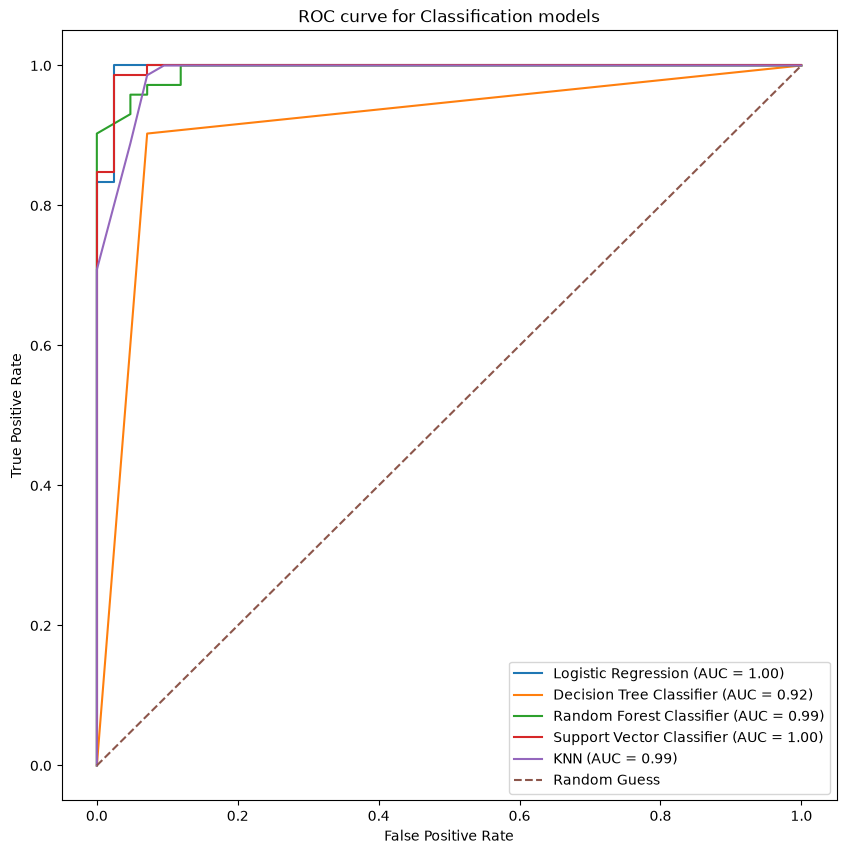

In [69]:
models=['Logistic Regression', 'Decision Tree Classifier', 'Random Forest Classifier', 'Support Vector Classifier', 'KNN']
fig, ax=plt.subplots(figsize=(10,10))
for i in models:
    fpr, tpr, _ = roc_curve(curve_dataframe['True'],curve_dataframe[i])
    roc_auc=auc(fpr, tpr)
    plt.plot(
        fpr,
        tpr,
        label=f"{i} (AUC = {roc_auc:.2f})"
    )
ax.plot([0,1],[0,1], label="Random Guess", linestyle="--")
ax.set_title("ROC curve for Classification models")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend()
plt.show()

#### **Conclusion**

1. Based on accuracy **Support Vector Classifier** is the best model and **Decision Tree Classifier** is the worst model.
2. Based on precision **Logistic Regression** is the best model and **Decision Tree Classifier** is the worst model.
3. Based on recall **Support Vector Classifier** and **k-Nearest Neighbor** are the best models and **Decision Tree Classifier** is the worst model.
4. Based on F1 Score **Support Vector Classifier** is the best model and **Decision Tree Classifier** is the worst model.